# Metabolic Health Explorer: preparación y exploración de los datos

¿Se puede priorizar a los adultos con más probabilidad de tener diabetes o prediabetes diagnosticada usando solo medidas baratas y fáciles de tomar (edad, género, IMC, cintura y presión), de modo que capturemos al menos el 75 % de los casos revisando como máximo al 40 % de la población?



## 1. Preparación de los datos

### 1.1. Librerías

In [1]:
import math
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

sns.set_style("darkgrid")
warnings.filterwarnings("ignore")

RUTA_RAW = Path("..") / "data" / "raw"
FIG_DIR = Path("..") / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

### 1.2. La tabla de diabetes

La fuente original es la tabla `DIQ_H.xpt` de NHANES 2013-2014 (cuestionario de diabetes). La descargamos de la página de datos del CDC y la leemos tal cual.

In [2]:
df_inicial = pd.read_sas(RUTA_RAW / "DIQ_H.xpt", format="xport")
df_inicial.shape

(9770, 54)

In [3]:
# un vistazo a las respuestas de diabetes
df_inicial[['SEQN', 'DIQ010']].head()

,SEQN,DIQ010
0,73557.0,1.0
1,73558.0,1.0
2,73559.0,1.0
3,73560.0,2.0
4,73561.0,2.0


Son 9.770 personas y 54 variables, bastante más que el subconjunto de UCI del 03. Veamos cómo respondieron la pregunta `DIQ010`.

In [4]:
df_inicial["DIQ010"].value_counts(dropna=False).sort_index()

DIQ010
1.0     737
2.0    8841
3.0     185
7.0       1
9.0       5
NaN       1
Name: count, dtype: int64

### 1.3. Variable objetivo

Según la documentación, `DIQ010` responde a la pregunta *¿alguna vez le han dicho que tiene diabetes?* Estos son los códigos:

| Código | Significado |
|---|---|
| 1 | Sí |
| 2 | No |
| 3 | Borderline (prediabetes) |
| 7 | Rehusó contestar |
| 9 | No sabe |
| Vacío | Sin dato |

Quitamos las respuestas 7, 9 y vacías. No nos dicen nada sobre si la persona tiene o no diabetes, y tampoco las podemos contar como "no".

In [5]:
df_etapa1 = df_inicial[df_inicial["DIQ010"].isin([1, 2, 3])].copy()
df_etapa1["DIQ010"].value_counts().sort_index()

DIQ010
1.0     737
2.0    8841
3.0     185
Name: count, dtype: int64

Quedan 737 personas con "Sí", 8.841 con "No" y 185 "Borderline", en total 9.763.

Los 185 borderline no dicen que tengan diabetes, pero sí les avisaron que están en prediabetes. Como lo que buscamos es decidir a quién conviene hacerle el examen de laboratorio, los contamos como positivos. Así el objetivo queda como *"tiene diabetes o prediabetes (1), o no (0)"*:

| Código | Significado | `Diabetes` |
|---|---|---|
| 1 | Sí | 1 |
| 2 | No | 0 |
| 3 | Borderline | 1 |

In [6]:
df_etapa1["Diabetes"] = df_etapa1["DIQ010"].isin([1, 3]).astype(int)
print(df_etapa1.shape)
df_etapa1["Diabetes"].value_counts(normalize=True).round(3)

(9763, 55)


Diabetes
0    0.906
1    0.094
Name: proportion, dtype: float64

Un 90,6 % son negativos y un 9,4 % positivos. Está bastante desbalanceado, pero eso es lo normal en datos reales de población general. (Ojo: esto es con todas las edades; cuando nos quedemos solo con los adultos, más abajo, el porcentaje de positivos sube a 14,8 %.)

### 1.4. Variables que no usamos

Antes de seguir, miramos los nulos de la tabla de diabetes separados por clase.

In [7]:
nulos = df_etapa1.drop(columns="SEQN").set_index("Diabetes").isna()
conteo = nulos.groupby(level=0).sum().astype(int)
pct = nulos.groupby(level=0).mean().mul(100).round(1)
tabla_nulos = pd.concat(
    [conteo.T.add_prefix("NA Diabetes="), pct.T.add_prefix("% NA Diabetes=")],
    axis=1,
)
tabla_nulos

Diabetes,NA Diabetes=0,NA Diabetes=1,% NA Diabetes=0,% NA Diabetes=1
DIQ010,0,0,0.0,0.0
DID040,8841,185,100.0,20.1
DIQ160,2559,922,28.9,100.0
DIQ170,2559,740,28.9,80.3
DIQ172,2559,740,28.9,80.3
DIQ175A,7602,825,86.0,89.5
DIQ175B,8356,862,94.5,93.5
DIQ175C,8746,905,98.9,98.2
DIQ175D,8511,882,96.3,95.7
DIQ175E,8758,913,99.1,99.0


Casi todas las preguntas están vacías para la mayoría de la gente. Revisando la documentación vimos por qué: la encuesta solo hace muchas de esas preguntas según lo que la persona contestó en `DIQ010`. Eso es una fuga de información (*data leakage*), porque la variable "delata" la respuesta:

- `DID040`, `DIQ080` y `DIQ230` a `DIQ360` solo tienen datos en quienes dijeron "Sí". Si hay dato, la persona ya tiene diabetes.
- `DIQ050` (toma insulina) y `DIQ070` (toma pastillas para el azúcar) son consecuencia del diagnóstico, no algo que lo anticipe.
- `DIQ170`, `DIQ172` y `DIQ180` pasan al revés: solo tienen datos en quienes no reportan diabetes o son borderline.

Por eso de esta tabla solo nos quedamos con el identificador (`SEQN`) y la etiqueta `Diabetes`.

In [8]:
objetivo = df_etapa1[["SEQN", "Diabetes"]].copy()
objetivo.head()

,SEQN,Diabetes
0,73557.0,1
1,73558.0,1
2,73559.0,1
3,73560.0,0
4,73561.0,0


### 1.5. Sumar info

NHANES tiene muchas más tablas del mismo ciclo, y todas se pueden unir por `SEQN`. Escogimos cuatro que traen medidas fáciles de tomar en una consulta, más el colesterol, que necesita una muestra de sangre (por eso después probamos los modelos con y sin laboratorio):

| Tabla | Qué trae | Variables que tomamos | Documentación |
|---|---|---|---|
| `DEMO_H` | Demografía | `RIDAGEYR` (edad), `RIAGENDR` (género), `RIDRETH3` (raza/etnia), `INDHHIN2` (ingreso del hogar), `INDFMIN2` (ingreso de la familia) | [enlace](https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2013/DataFiles/DEMO_H.htm) |
| `BMX_H` | Medidas corporales | `BMXBMI` (IMC), `BMXWAIST` (cintura en cm) | [enlace](https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2013/DataFiles/BMX_H.htm) |
| `BPX_H` | Presión arterial | `BPXSY1` (sistólica), `BPXDI1` (diastólica), primera lectura en mmHg | [enlace](https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2013/DataFiles/BPX_H.htm) |
| `TCHOL_H` | Colesterol total | `LBXTC` (mg/dL) | [enlace](https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2013/DataFiles/TCHOL_H.htm) |
| `HDL_H` | Colesterol HDL | `LBDHDD` (mg/dL) | [enlace](https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2013/DataFiles/HDL_H.htm) |


In [9]:
Demografia = pd.read_sas(RUTA_RAW / "DEMO_H.xpt", format="xport")
Medidas_c = pd.read_sas(RUTA_RAW / "BMX_H.xpt", format="xport")
Presion_a = pd.read_sas(RUTA_RAW / "BPX_H.xpt", format="xport")
Colesterol_t = pd.read_sas(RUTA_RAW / "TCHOL_H.xpt", format="xport")
Colesterol_hdl = pd.read_sas(RUTA_RAW / "HDL_H.xpt", format="xport")

tablas = [
    Demografia[["SEQN", "RIDAGEYR", "RIAGENDR", "RIDRETH3", "INDHHIN2", "INDFMIN2"]].copy(),
    Medidas_c[["SEQN", "BMXBMI", "BMXWAIST"]].copy(),
    Presion_a[["SEQN", "BPXSY1", "BPXDI1"]].copy(),
    Colesterol_t[["SEQN", "LBXTC"]].copy(),
    Colesterol_hdl[["SEQN", "LBDHDD"]].copy(),
]

### 1.6. Unión de la base final

Unimos todo a partir de la tabla del objetivo, de modo que no se pierda ninguna persona. Después verificamos que no se hayan perdido ni duplicado filas.

In [10]:
for t in [objetivo] + tablas:
    t["SEQN"] = t["SEQN"].astype(int)

df_consolidado = objetivo.copy()
for t in tablas:
    df_consolidado = df_consolidado.merge(t, on="SEQN", how="left")

print(df_consolidado.shape)
print("Mismas filas que el objetivo:", len(df_consolidado) == len(objetivo))
print("SEQN sin duplicados:", df_consolidado["SEQN"].is_unique)

(9763, 13)
Mismas filas que el objetivo: True
SEQN sin duplicados: True


El SEQN solo servía para unir, así que lo quitamos. También renombramos las columnas para leerlas mejor.

In [11]:
df_consolidado = df_consolidado.drop(columns="SEQN").rename(columns={
    "RIDAGEYR": "Edad",
    "RIAGENDR": "Genero",
    "RIDRETH3": "Raza_Etnia",
    "INDHHIN2": "Ingreso_Hogar",
    "INDFMIN2": "Ingreso_Familia",
    "BMXBMI": "IMC",
    "BMXWAIST": "Cintura_cm",
    "BPXSY1": "Presion_Sistolica",
    "BPXDI1": "Presion_Diastolica",
    "LBXTC": "Colesterol_Total",
    "LBDHDD": "Colesterol_HDL",
})

df_consolidado.to_csv(RUTA_RAW / "NHANES_consolidado.csv", index=False)
df_consolidado.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9763 entries, 0 to 9762
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Diabetes            9763 non-null   int64  
 1   Edad                9763 non-null   float64
 2   Genero              9763 non-null   float64
 3   Raza_Etnia          9763 non-null   float64
 4   Ingreso_Hogar       9634 non-null   float64
 5   Ingreso_Familia     9644 non-null   float64
 6   IMC                 9049 non-null   float64
 7   Cintura_cm          8655 non-null   float64
 8   Presion_Sistolica   7167 non-null   float64
 9   Presion_Diastolica  7167 non-null   float64
 10  Colesterol_Total    7619 non-null   float64
 11  Colesterol_HDL      7619 non-null   float64
dtypes: float64(11), int64(1)
memory usage: 915.4 KB


In [12]:
# así quedó la base consolidada
print(df_consolidado.shape)
df_consolidado.head()

(9763, 12)


,Diabetes,Edad,Genero,Raza_Etnia,Ingreso_Hogar,Ingreso_Familia,IMC,Cintura_cm,Presion_Sistolica,Presion_Diastolica,Colesterol_Total,Colesterol_HDL
0,1,69.0,1.0,4.0,4.0,4.0,26.7,100.0,122.0,72.0,167.0,65.0
1,1,54.0,1.0,3.0,7.0,7.0,28.6,107.6,156.0,62.0,170.0,50.0
2,1,72.0,1.0,3.0,10.0,10.0,28.9,109.2,140.0,90.0,126.0,60.0
3,0,9.0,1.0,3.0,9.0,9.0,17.1,61.0,108.0,38.0,168.0,61.0
4,0,73.0,2.0,3.0,15.0,15.0,19.7,NaN,136.0,86.0,201.0,85.0


## 2. Base completa

In [13]:
df = pd.read_csv(RUTA_RAW / "NHANES_consolidado.csv")
print(df.shape)
pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "n_unicos": df.nunique(),
    "ejemplo": df.iloc[0],
})

(9763, 12)


,tipo,n_unicos,ejemplo
Diabetes,int64,2,1.0
Edad,float64,80,69.0
Genero,float64,2,1.0
Raza_Etnia,float64,6,4.0
Ingreso_Hogar,float64,16,4.0
Ingreso_Familia,float64,16,4.0
IMC,float64,440,26.7
Cintura_cm,float64,1038,100.0
Presion_Sistolica,float64,71,122.0
Presion_Diastolica,float64,59,72.0


In [14]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Diabetes,9763.0,0.09,0.29,0.0,0.0,0.0,0.0,1.0
Edad,9763.0,32.79,24.05,1.0,11.0,29.0,53.0,80.0
Genero,9763.0,1.51,0.50,1.0,1.0,2.0,2.0,2.0
Raza_Etnia,9763.0,3.30,1.61,1.0,2.0,3.0,4.0,7.0
Ingreso_Hogar,9634.0,10.91,13.94,1.0,5.0,8.0,14.0,99.0
Ingreso_Familia,9644.0,10.52,13.68,1.0,5.0,7.0,14.0,99.0
IMC,9049.0,25.68,7.96,12.1,19.7,24.7,30.2,82.9
Cintura_cm,8655.0,87.26,22.54,40.2,71.2,87.8,102.7,177.9
Presion_Sistolica,7167.0,118.12,18.08,66.0,106.0,116.0,128.0,228.0
Presion_Diastolica,7167.0,65.77,14.96,0.0,58.0,66.0,76.0,122.0


- **Edad:** va de 1 a 80 años, con mediana de 29. Hay muchos niños en la base, así que toca decidir si se quedan (lo resolvemos en 3.1)
- **Presión diastólica:** el mínimo es 0, que no es un valor posible en una persona viva. Parece un error de captura.
- **IMC:** el promedio es 25,7 y el máximo 82,9. Es un valor extremo, pero lo revisamos más adelante antes de decidir qué hacer con él.
- **Presión sistólica y colesterol total:** los promedios (118 mmHg y 180 mg/dL) están en rangos normales.
- **Género y raza/etnia** vienen como números (1, 2, 3...) aunque son categorías.

## 3. Exploración adultos

Aquí revisamos los datos con la pregunta de negocio en mente. Queremos saber a quién incluimos, qué tan confiables son los datos, qué variables y grupos se diferencian, y si hay suficiente señal para priorizar.

### 3.1. Excluir a los niños

La prueba de diabetes se piensa para adultos, pero la base tiene niños. Miramos qué pasa con cada grupo.

In [15]:
tasa_grupo = (
    df.assign(Grupo=np.where(df["Edad"] >= 18, "Adultos (>= 18)", "Menores (< 18)"))
      .groupby("Grupo")["Diabetes"]
      .agg(Registros="size", Positivos="sum", Tasa_pct="mean")
)
tasa_grupo["Tasa_pct"] = (tasa_grupo["Tasa_pct"] * 100).round(1)
tasa_grupo

,Registros,Positivos,Tasa_pct
Grupo,,,
Adultos (>= 18),6110,902,14.8
Menores (< 18),3653,20,0.5


Entre los menores solo 20 personas (0,5 %) tienen diabetes o prediabetes. Entre los adultos son 902 (14,8 %). Si dejamos a los niños, el modelo aprendería casi que "niño = sin diabetes", y eso no aporta. Nos quedamos con los adultos.

In [16]:
adultos = df[df["Edad"] >= 18].copy()
print(f"Registros totales: {len(df):,}  de aca  adultos: {len(adultos):,}")
print(f"Positivos (diabetes o prediabetes): {adultos['Diabetes'].sum():,}  ({adultos['Diabetes'].mean():.1%})")

Registros totales: 9,763  de aca  adultos: 6,110
Positivos (diabetes o prediabetes): 902  (14.8%)


In [17]:
# ojo a los adultos
print(adultos.shape)
adultos.head()

(6110, 12)


,Diabetes,Edad,Genero,Raza_Etnia,Ingreso_Hogar,Ingreso_Familia,IMC,Cintura_cm,Presion_Sistolica,Presion_Diastolica,Colesterol_Total,Colesterol_HDL
0,1,69.0,1.0,4.0,4.0,4.0,26.7,100.0,122.0,72.0,167.0,65.0
1,1,54.0,1.0,3.0,7.0,7.0,28.6,107.6,156.0,62.0,170.0,50.0
2,1,72.0,1.0,3.0,10.0,10.0,28.9,109.2,140.0,90.0,126.0,60.0
4,0,73.0,2.0,3.0,15.0,15.0,19.7,NaN,136.0,86.0,201.0,85.0
5,0,56.0,1.0,1.0,9.0,9.0,41.7,123.1,160.0,84.0,226.0,38.0


### 3.2. Limpieza y recodificación

- **Etiquetas:** Genero y Raza_Etnia pasan de números a texto.
- **Ingreso:** el ingreso del hogar y el de la familia están casi igual de correlacionados (0,92), así que nos quedamos con el del hogar. Lo agrupamos en tres niveles. Los códigos 77 (rehusó) y 99 (no sabe) pasan a nulo, y el 12 ("20 mil dólares o más") también, porque no dice cuánto más.
- **Presión diastólica:** los valores del orden de 1e-79 son ceros que el formato SAS guarda con ese ruido. Son lecturas no válidas, así que los pasamos a nulo.

In [18]:
print("Correlación entre ingreso del hogar y de la familia:",
      round(adultos[["Ingreso_Hogar", "Ingreso_Familia"]].corr().iloc[0, 1], 2))

adultos["Genero"] = adultos["Genero"].map({1: "Hombre", 2: "Mujer"})
adultos["Raza_Etnia"] = adultos["Raza_Etnia"].map({
    1: "Mexicano-americano", 2: "Otro hispano", 3: "Blanco no hispano",
    4: "Negro no hispano", 6: "Asiático no hispano", 7: "Otra / multirracial",
})

def nivel_ingreso(codigo):
    if codigo in (1, 2, 3, 4, 13):
        return "Bajo (< 20 mil USD)"
    if codigo in (5, 6, 7, 8, 9, 10):
        return "Medio (20 - 75 mil USD)"
    if codigo in (14, 15):
        return "Alto (>= 75 mil USD)"
    return np.nan  # 12, 77, 99 y vacíos

adultos["Ingreso_Nivel"] = adultos["Ingreso_Hogar"].map(nivel_ingreso)
adultos["Ingreso_Nivel"] = pd.Categorical(
    adultos["Ingreso_Nivel"], ordered=True,
    categories=["Bajo (< 20 mil USD)", "Medio (20 - 75 mil USD)", "Alto (>= 75 mil USD)"],
)
adultos = adultos.drop(columns=["Ingreso_Hogar", "Ingreso_Familia"])

n_diast = (adultos["Presion_Diastolica"] < 10).sum()
adultos.loc[adultos["Presion_Diastolica"] < 10, "Presion_Diastolica"] = np.nan
print(f"Lecturas diastólicas no válidas pasadas a nulo: {n_diast}")

NUM = ["Edad", "IMC", "Cintura_cm", "Presion_Sistolica", "Presion_Diastolica",
       "Colesterol_Total", "Colesterol_HDL"]
adultos.shape

Correlación entre ingreso del hogar y de la familia: 0.92
Lecturas diastólicas no válidas pasadas a nulo: 32


(6110, 11)

In [19]:
# cómo quedaron las columnas después de la limpieza
print(adultos.shape)
adultos[['Genero', 'Raza_Etnia', 'Ingreso_Nivel', 'Presion_Diastolica']].head()

(6110, 11)


,Genero,Raza_Etnia,Ingreso_Nivel,Presion_Diastolica
0,Hombre,Negro no hispano,Bajo (< 20 mil USD),72.0
1,Hombre,Blanco no hispano,Medio (20 - 75 mil USD),62.0
2,Hombre,Blanco no hispano,Medio (20 - 75 mil USD),90.0
4,Mujer,Blanco no hispano,Alto (>= 75 mil USD),86.0
5,Hombre,Mexicano-americano,Medio (20 - 75 mil USD),84.0


### 3.3. Variable objetivo en adultos

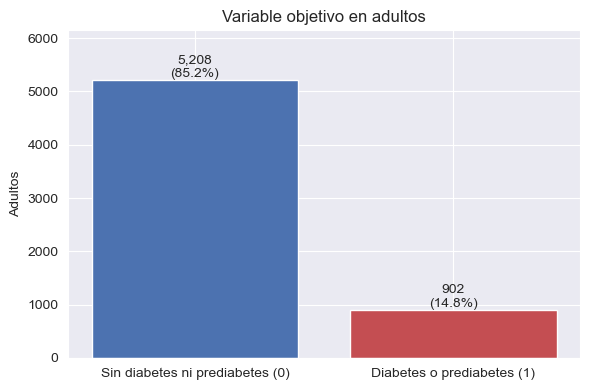

Por cada positivo hay 5.8 negativos


In [20]:
conteo = adultos["Diabetes"].value_counts().sort_index()
etiquetas = ["Sin diabetes ni prediabetes (0)", "Diabetes o prediabetes (1)"]

fig, ax = plt.subplots(figsize=(6, 4))
barras = ax.bar(etiquetas, conteo.values, color=["#4C72B0", "#C44E52"])
for b, v in zip(barras, conteo.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 60, f"{v:,}\n({v / conteo.sum():.1%})", ha="center")
ax.set_ylabel("Adultos")
ax.set_ylim(0, conteo.max() * 1.18)
ax.set_title("Variable objetivo en adultos")
plt.tight_layout()
plt.savefig(FIG_DIR / "eda_objetivo_adultos.png", dpi=150)
plt.show()
print(f"Por cada positivo hay {conteo[0] / conteo[1]:.1f} negativos")

Tenemos 902 positivos contra 5.208 negativos, unos 5,8 negativos por cada positivo. 

### 3.4. Calidad de los datos: nulos y valores raros

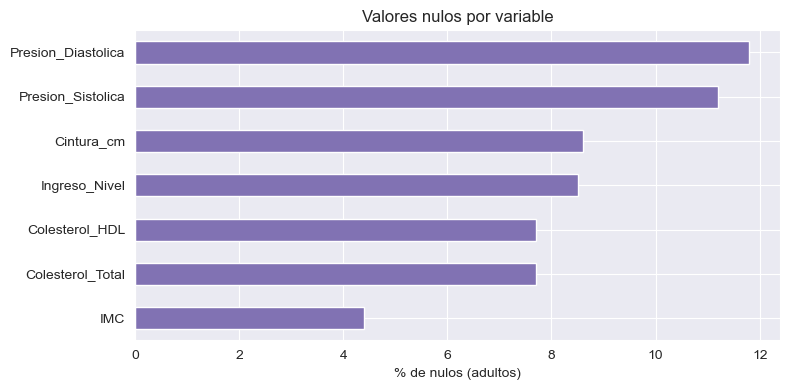

,% nulos (Diabetes=0),% nulos (Diabetes=1),% nulos (total)
Presion_Diastolica,11.5,13.4,11.8
Presion_Sistolica,11.0,12.4,11.2
Cintura_cm,8.4,10.1,8.6
Ingreso_Nivel,8.7,7.1,8.5
Colesterol_Total,7.8,7.3,7.7
Colesterol_HDL,7.8,7.3,7.7
IMC,4.4,4.1,4.4


In [21]:
nulos_cls = adultos.isna().groupby(adultos["Diabetes"]).mean().mul(100).round(1).T
nulos_cls.columns = ["% nulos (Diabetes=0)", "% nulos (Diabetes=1)"]
nulos_cls["% nulos (total)"] = adultos.isna().mean().mul(100).round(1)
nulos_cls = nulos_cls[nulos_cls["% nulos (total)"] > 0].sort_values("% nulos (total)", ascending=False)

fig, ax = plt.subplots(figsize=(8, 4))
nulos_cls["% nulos (total)"].sort_values().plot.barh(ax=ax, color="#8172B3")
ax.set_xlabel("% de nulos (adultos)")
ax.set_title("Valores nulos por variable")
plt.tight_layout()
plt.savefig(FIG_DIR / "eda_nulos.png", dpi=150)
plt.show()
nulos_cls

Faltan entre 4 % y 12 % de los datos según la variable, sobre todo en presión arterial, cintura e ingreso. Lo bueno es que el porcentaje es casi igual en positivos y negativos, así que el hecho de que falte un dato no delata la clase. Entonces, en lugar de botar filas, vamos a rellenar con la mediana dentro del pipeline, calculada solo con los datos de entrenamiento.

In [22]:
def resumen_atipicos(d, cols):
    filas = []
    for col in cols:
        s = d[col].dropna()
        q1, q3 = s.quantile([0.25, 0.75])
        iqr = q3 - q1
        lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        n = int(((s < lim_inf) | (s > lim_sup)).sum())
        filas.append({"Variable": col, "Mínimo": s.min(), "Mediana": s.median(), "Máximo": s.max(),
                      "Límite inf. (IQR)": lim_inf, "Límite sup. (IQR)": lim_sup,
                      "Atípicos": n, "% atípicos": round(n / len(s) * 100, 1)})
    return pd.DataFrame(filas).set_index("Variable").round(1)

resumen_atipicos(adultos, NUM)

,Mínimo,Mediana,Máximo,Límite inf. (IQR),Límite sup. (IQR),Atípicos,% atípicos
Variable,,,,,,,
Edad,18.0,47.0,80.0,-13.0,107.0,0,0.0
IMC,14.1,27.7,82.9,11.1,45.2,185,3.2
Cintura_cm,55.5,97.0,177.9,53.8,140.7,103,1.8
Presion_Sistolica,66.0,120.0,228.0,77.0,165.0,167,3.1
Presion_Diastolica,22.0,70.0,122.0,38.0,102.0,61,1.1
Colesterol_Total,69.0,184.0,813.0,79.5,291.5,67,1.2
Colesterol_HDL,10.0,50.0,173.0,13.5,89.5,146,2.6


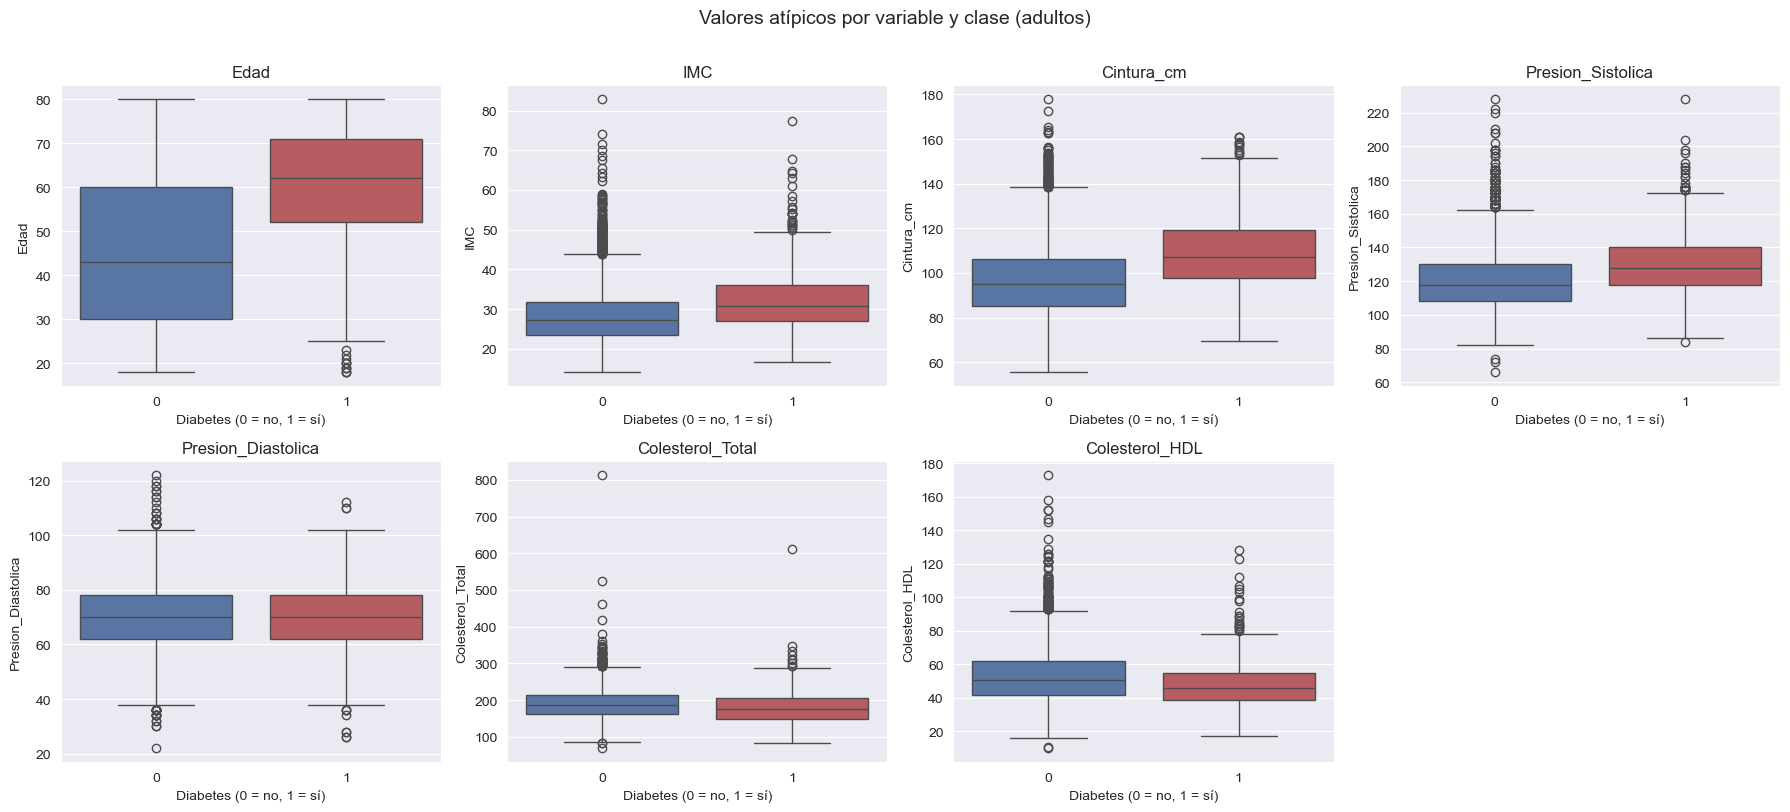

In [23]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.flatten(), NUM):
    sns.boxplot(data=adultos, x="Diabetes", y=col, ax=ax,
                palette=["#4C72B0", "#C44E52"], hue="Diabetes", legend=False)
    ax.set_xlabel("Diabetes (0 = no, 1 = sí)")
    ax.set_title(col)
axes.flatten()[-1].axis("off")
plt.suptitle("Valores atípicos por variable y clase (adultos)", y=1.01, fontsize=14)
plt.tight_layout()
plt.savefig(FIG_DIR / "eda_boxplots_clase.png", dpi=150, bbox_inches="tight")
plt.show()

Los atípicos son pocos (entre 1 % y 3 % por variable) y son valores que sí pueden darse: un IMC de 82,9 es obesidad extrema y un colesterol de 813 es una hipercolesterolemia severa. No parecen errores de captura, y además esas personas son justamente las que nos interesan. Entonces no los quitamos. 

### 3.5. Diferencias de positivos y negativos

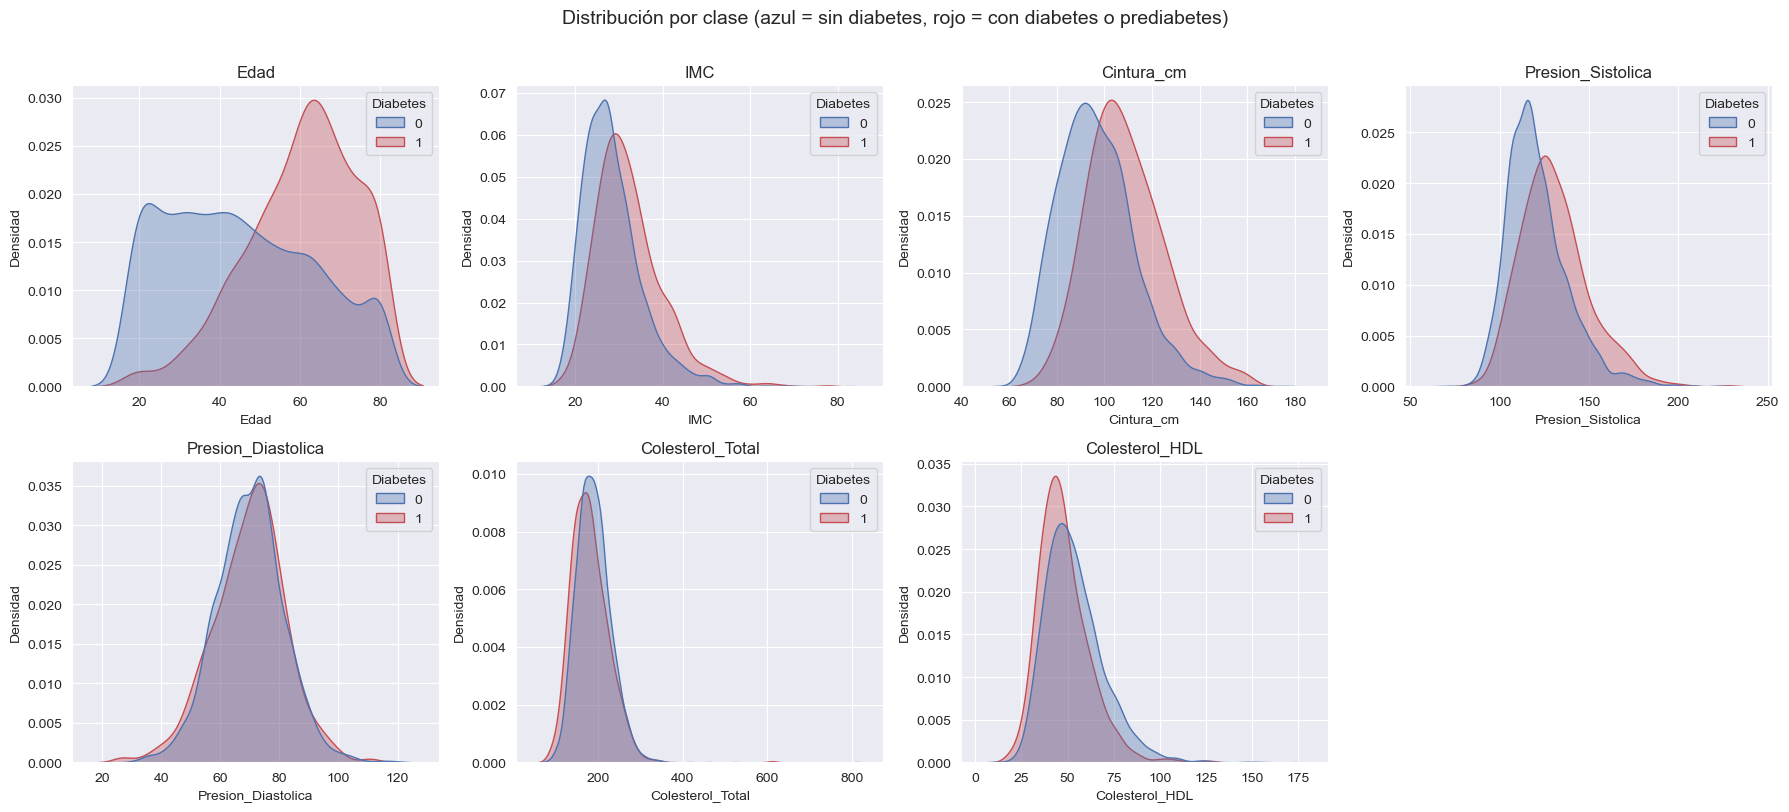

In [24]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.flatten(), NUM):
    sns.kdeplot(data=adultos, x=col, hue="Diabetes", common_norm=False, fill=True, alpha=0.35,
                palette=["#4C72B0", "#C44E52"], ax=ax)
    ax.set_title(col)
    ax.set_ylabel("Densidad")
axes.flatten()[-1].axis("off")
plt.suptitle("Distribución por clase (azul = sin diabetes, rojo = con diabetes o prediabetes)", y=1.01, fontsize=14)
plt.tight_layout()
plt.savefig(FIG_DIR / "eda_distribuciones_clase.png", dpi=150, bbox_inches="tight")
plt.show()

In [25]:
resultados = []
for col in NUM:
    pos = adultos.loc[adultos["Diabetes"] == 1, col].dropna()
    neg = adultos.loc[adultos["Diabetes"] == 0, col].dropna()
    u = stats.mannwhitneyu(pos, neg)
    resultados.append({
        "Variable": col,
        "Mediana (Diabetes=0)": neg.median(),
        "Mediana (Diabetes=1)": pos.median(),
        "Diferencia": pos.median() - neg.median(),
        "AUC univariado": round(u.statistic / (len(pos) * len(neg)), 3),
        "p-valor (Mann-Whitney)": f"{u.pvalue:.1e}",
    })
pd.DataFrame(resultados).set_index("Variable").round(3)

,Mediana (Diabetes=0),Mediana (Diabetes=1),Diferencia,AUC univariado,p-valor (Mann-Whitney)
Variable,,,,,
Edad,43.0,62.0,19.0,0.742,2.6e-119
IMC,27.2,30.9,3.7,0.663,5.3e-53
Cintura_cm,95.0,107.2,12.2,0.711,1.3e-82
Presion_Sistolica,118.0,128.0,10.0,0.657,2.7e-45
Presion_Diastolica,70.0,70.0,0.0,0.503,7.6e-01
Colesterol_Total,186.0,176.0,-10.0,0.430,1.2e-10
Colesterol_HDL,51.0,46.0,-5.0,0.390,3.3e-24


El AUC univariado:

- **Edad (0,74):** es la que mejor separa. La mediana es de 62 años en los positivos y de 43 en los negativos.
- **Cintura (0,71), IMC (0,66) y presión sistólica (0,66):** son más altas en los positivos (107 vs 95 cm, 30,9 vs 27,2 y 128 vs 118 mmHg).
- **HDL (0,39):** es más bajo en los positivos (46 vs 51), lo que cuadra con un perfil metabólico de riesgo.
- **Presión diastólica (0,50):** no separa nada.
- **Colesterol total:** sale más bajo en los positivos (176 vs 186), al revés de lo que uno esperaría. Nuestra sospecha es que muchas de esas personas ya están diagnosticadas y toman medicamentos que bajan el colesterol. No lo probamos, pero es una razón más para no leer el modelo como causa y efecto.

### 3.6. Porcentaje de casos por grupo

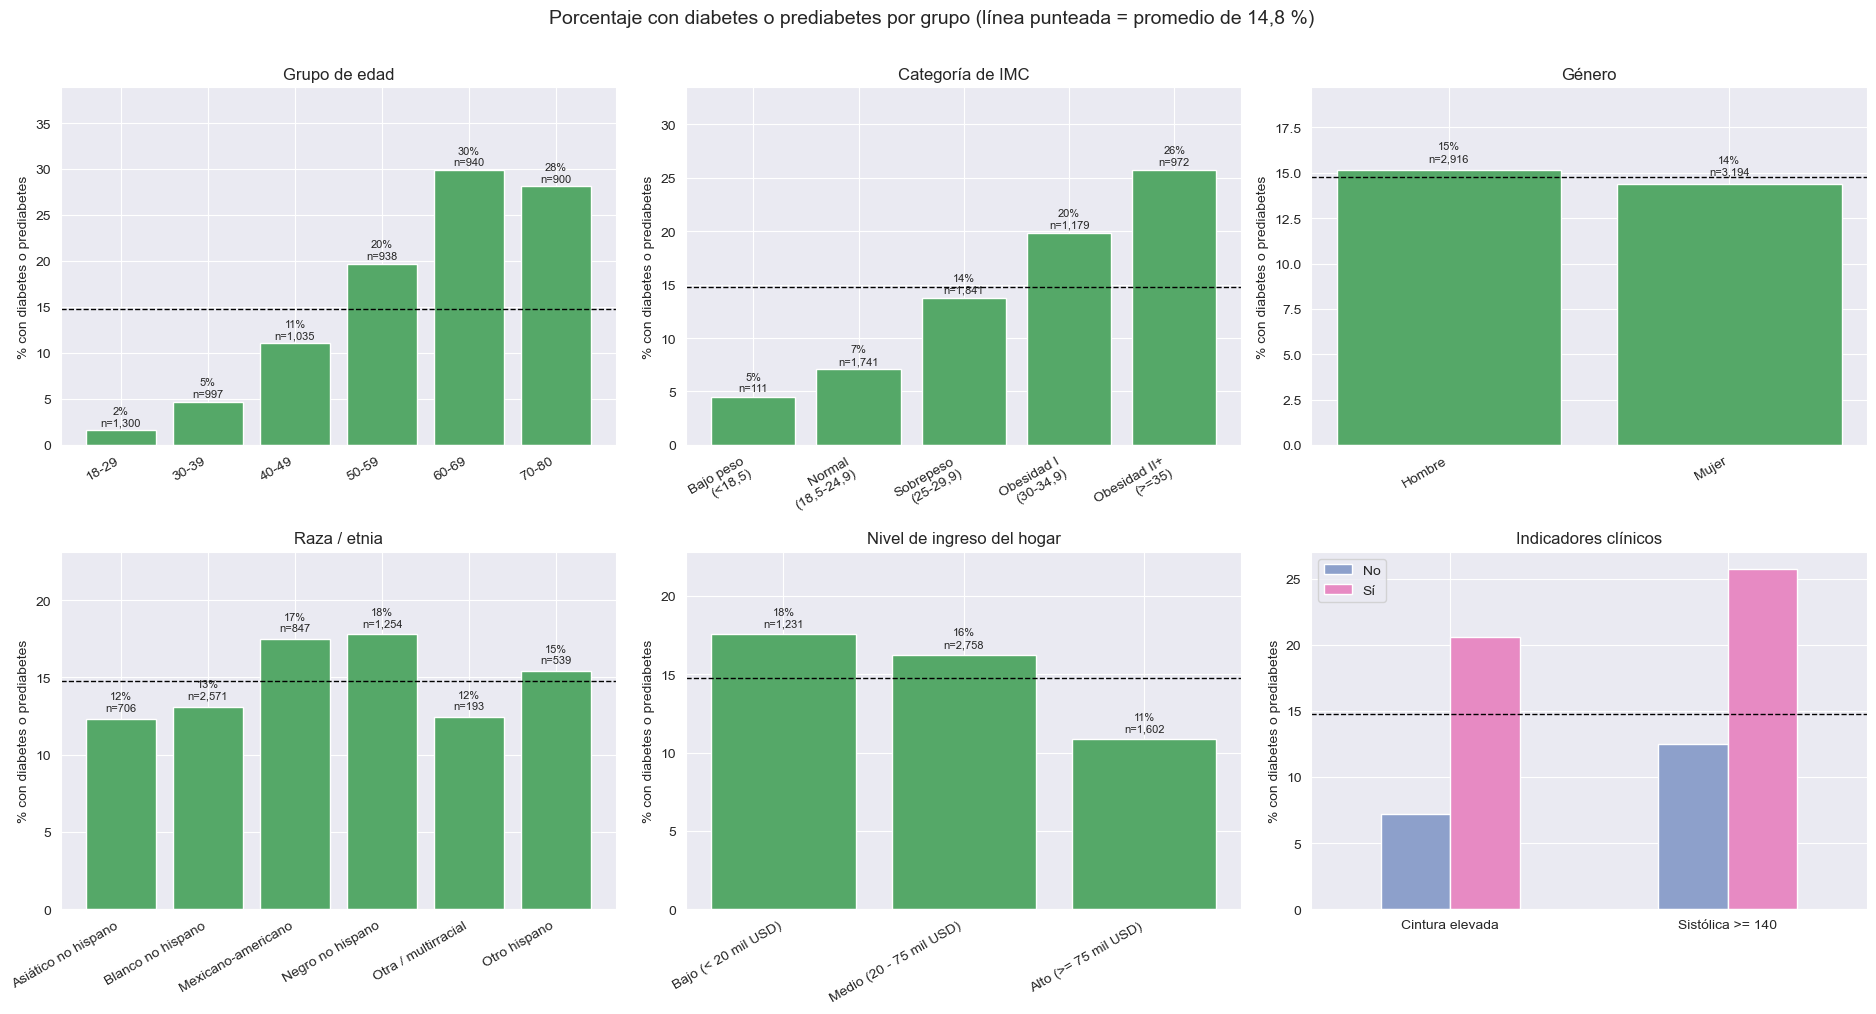

In [26]:
adultos["Grupo_Edad"] = pd.cut(adultos["Edad"], [17, 29, 39, 49, 59, 69, 80],
                               labels=["18-29", "30-39", "40-49", "50-59", "60-69", "70-80"])
adultos["Categoria_IMC"] = pd.cut(adultos["IMC"], [0, 18.5, 25, 30, 35, 100], right=False,
                                  labels=["Bajo peso\n(<18,5)", "Normal\n(18,5-24,9)", "Sobrepeso\n(25-29,9)",
                                          "Obesidad I\n(30-34,9)", "Obesidad II+\n(>=35)"])
# Cintura elevada: más de 102 cm en hombres y más de 88 cm en mujeres
adultos["Cintura_elevada"] = np.where(adultos["Cintura_cm"].isna(), np.nan,
    np.where(((adultos["Genero"] == "Hombre") & (adultos["Cintura_cm"] > 102)) |
             ((adultos["Genero"] == "Mujer") & (adultos["Cintura_cm"] > 88)), 1.0, 0.0))
adultos["Hipertension_sistolica"] = np.where(adultos["Presion_Sistolica"].isna(), np.nan,
                                             (adultos["Presion_Sistolica"] >= 140).astype(float))

def tasa(col):
    t = adultos.groupby(col, observed=True)["Diabetes"].agg(["mean", "size"])
    t["mean"] *= 100
    return t

grupos = [("Grupo_Edad", "Grupo de edad"), ("Categoria_IMC", "Categoría de IMC"),
          ("Genero", "Género"), ("Raza_Etnia", "Raza / etnia"),
          ("Ingreso_Nivel", "Nivel de ingreso del hogar")]
tasa_global = adultos["Diabetes"].mean() * 100

fig, axes = plt.subplots(2, 3, figsize=(19, 10))
for ax, (col, titulo) in zip(axes.flatten(), grupos):
    t = tasa(col)
    ax.bar(range(len(t)), t["mean"], color="#55A868")
    ax.set_xticks(range(len(t)))
    ax.set_xticklabels([str(i) for i in t.index], rotation=30, ha="right")
    for i, (m, n) in enumerate(zip(t["mean"], t["size"])):
        ax.text(i, m + 0.5, f"{m:.0f}%\nn={n:,}", ha="center", fontsize=8)
    ax.axhline(tasa_global, color="k", ls="--", lw=1)
    ax.set_title(titulo)
    ax.set_ylabel("% con diabetes o prediabetes")
    ax.set_ylim(0, t["mean"].max() * 1.3)

ind = pd.DataFrame({
    "Cintura elevada": adultos.groupby("Cintura_elevada")["Diabetes"].mean().mul(100),
    "Sistólica >= 140": adultos.groupby("Hipertension_sistolica")["Diabetes"].mean().mul(100),
}).T
ind.columns = ["No", "Sí"]
ind.plot.bar(ax=axes[1, 2], color=["#8DA0CB", "#E78AC3"], rot=0)
axes[1, 2].axhline(tasa_global, color="k", ls="--", lw=1)
axes[1, 2].set_title("Indicadores clínicos")
axes[1, 2].set_ylabel("% con diabetes o prediabetes")

plt.suptitle("Porcentaje con diabetes o prediabetes por grupo (línea punteada = promedio de 14,8 %)", y=1.01, fontsize=14)
plt.tight_layout()
plt.savefig(FIG_DIR / "eda_tasas_por_grupo.png", dpi=150, bbox_inches="tight")
plt.show()

In [27]:
# revisamos las columnas nuevas de grupos
adultos[['Edad', 'Grupo_Edad', 'IMC', 'Categoria_IMC', 'Cintura_cm', 'Cintura_elevada']].head()

,Edad,Grupo_Edad,IMC,Categoria_IMC,Cintura_cm,Cintura_elevada
0,69.0,60-69,26.7,"Sobrepeso\n(25-29,9)",100.0,0.0
1,54.0,50-59,28.6,"Sobrepeso\n(25-29,9)",107.6,1.0
2,72.0,70-80,28.9,"Sobrepeso\n(25-29,9)",109.2,1.0
4,73.0,70-80,19.7,"Normal\n(18,5-24,9)",NaN,NaN
5,56.0,50-59,41.7,Obesidad II+\n(>=35),123.1,1.0


In [28]:
pd.concat({
    "Edad": tasa("Grupo_Edad"), "IMC": tasa("Categoria_IMC"),
    "Género": tasa("Genero"), "Raza/etnia": tasa("Raza_Etnia"),
    "Ingreso": tasa("Ingreso_Nivel"),
}).rename(columns={"mean": "% positivos", "size": "n"}).round(1)

% positivos     n
Edad       18-29                            1.6  1300
           30-39                            4.7   997
           40-49                           11.1  1035
           50-59                           19.7   938
           60-69                           29.9   940
           70-80                           28.1   900
IMC        Bajo peso\n(<18,5)               4.5   111
           Normal\n(18,5-24,9)              7.1  1741
           Sobrepeso\n(25-29,9)            13.7  1841
           Obesidad I\n(30-34,9)           19.8  1179
           Obesidad II+\n(>=35)            25.7   972
Género     Hombre                          15.2  2916
           Mujer                           14.4  3194
Raza/etnia Asiático no hispano             12.3   706
           Blanco no hispano               13.1  2571
           Mexicano-americano              17.5   847
           Negro no hispano                17.8  1254
           Otra / multirracial             12.4   193
           Otro hispano                    15.4   539
Ingreso    Bajo (< 20 mil USD)             17.5  1231
           Medio (20 - 75 mil USD)         16.2  2758
           Alto (>= 75 mil USD)            10.9  1602

In [29]:
for col in ["Genero", "Raza_Etnia", "Ingreso_Nivel"]:
    chi2, p, _, _ = stats.chi2_contingency(pd.crosstab(adultos[col], adultos["Diabetes"]))
    print(f"{col:15s} chi2 = {chi2:7.1f}   p = {p:.1e}")

Genero          chi2 =     0.6   p = 4.3e-01
Raza_Etnia      chi2 =    24.0   p = 2.2e-04
Ingreso_Nivel   chi2 =    31.1   p = 1.7e-07


- **Edad:** es el patrón más fuerte. De 1,6 % entre los 18 y 29 años se pasa a cerca de 30 % entre los 60 y 69, casi 19 veces más.
- **IMC:** sube de forma pareja, de 7 % con peso normal a 26 % con obesidad II o más.
- **Cintura y presión:** con la cintura elevada el porcentaje es de 20,6 %, contra 7,2 % sin ella. Con sistólica de 140 o más es de 26 %, contra 13 %.
- **Género:** casi no hay diferencia (15,2 % en hombres y 14,4 % en mujeres), y no es estadísticamente significativa. Solo, el género aporta poco.
- **Raza/etnia:** hay diferencias moderadas (de 12 % a 18 %) y significativas. Las vamos a usar para describir y controlar, pero no para decidir a quién priorizar, porque sería injusto.
- **Ingreso:** los hogares de ingreso alto tienen menos casos (10,9 %) que los de ingreso medio (16,2 %) y bajo (17,5 %). Lo tomamos como contexto, ya que puede reflejar quién tiene acceso a un diagnóstico.

### 3.7. Correlaciones

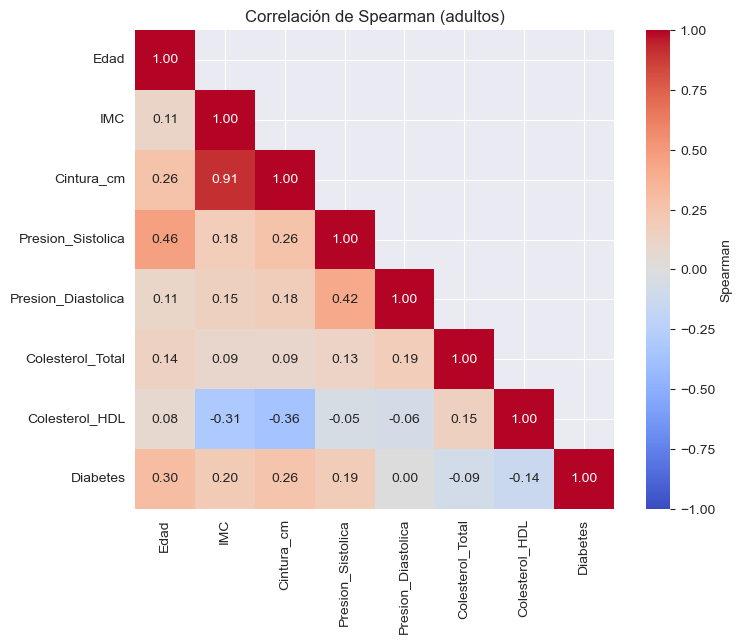

,Spearman con Diabetes
Edad,0.297
Cintura_cm,0.258
IMC,0.200
Presion_Sistolica,0.192
Colesterol_HDL,-0.135
Colesterol_Total,-0.086
Presion_Diastolica,0.004


In [30]:
corr = adultos[NUM + ["Diabetes"]].corr(method="spearman")
mascara = np.triu(np.ones_like(corr, dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(corr, mask=mascara, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            vmin=-1, vmax=1, square=True, cbar_kws={"label": "Spearman"}, ax=ax)
ax.set_title("Correlación de Spearman (adultos)")
plt.tight_layout()
plt.savefig(FIG_DIR / "eda_correlacion_spearman.png", dpi=150)
plt.show()

corr["Diabetes"].drop("Diabetes").sort_values(key=abs, ascending=False).round(3).to_frame("Spearman con Diabetes")

- Las relaciones con el objetivo son moderadas: edad (0,30), cintura (0,26), IMC (0,20) y sistólica (0,19), y HDL va en sentido contrario (-0,14). Es lo que se espera de un problema con muchas causas, donde ninguna variable alcanza sola.
- **IMC y cintura casi dicen lo mismo (0,91).** En una regresión logística esto puede traer problemas de multicolinealidad, así que probaremos con una sola de las dos o con regularización (eso lo probó Mafe en el 07 y da casi lo mismo). Con árboles no importa.
- Edad y presión sistólica también van de la mano (0,46).
- La diastólica no se relaciona con el objetivo (0,00), así que es candidata a salir del modelo.

### 3.8. Edad e IMC

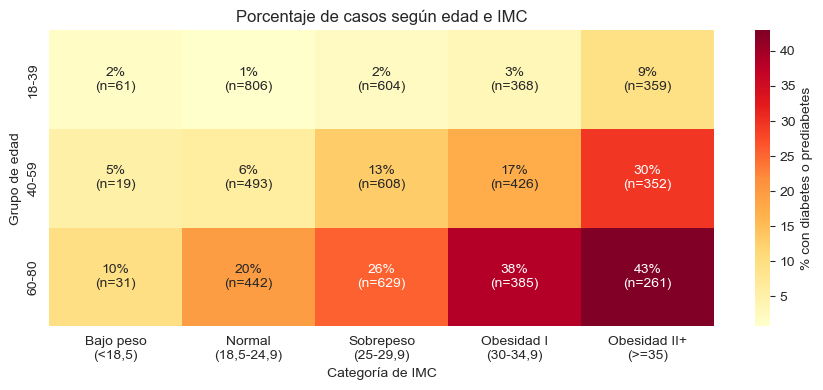

In [31]:
adultos["Edad_3"] = pd.cut(adultos["Edad"], [17, 39, 59, 80], labels=["18-39", "40-59", "60-80"])
tab_tasa = adultos.pivot_table(index="Edad_3", columns="Categoria_IMC", values="Diabetes",
                               aggfunc="mean", observed=True) * 100
tab_n = adultos.pivot_table(index="Edad_3", columns="Categoria_IMC", values="Diabetes",
                            aggfunc="size", observed=True)
anot = tab_tasa.round(0).astype(int).astype(str) + "%\n(n=" + tab_n.astype(str) + ")"

fig, ax = plt.subplots(figsize=(9, 4))
sns.heatmap(tab_tasa, annot=anot, fmt="", cmap="YlOrRd",
            cbar_kws={"label": "% con diabetes o prediabetes"}, ax=ax)
ax.set_xlabel("Categoría de IMC")
ax.set_ylabel("Grupo de edad")
ax.set_title("Porcentaje de casos según edad e IMC")
plt.tight_layout()
plt.savefig(FIG_DIR / "eda_interaccion_edad_imc.png", dpi=150)
plt.show()

Se refuerzan entre sí. Entre los 18 y 39 años el porcentaje pasa de 0,7 % con peso normal a 9,5 % con obesidad II o más. Entre los 60 y 80 pasa de 20 % a 43 %. Es decir, con el mismo IMC, ser mayor pesa mucho, y con la misma edad, la obesidad también.

Por eso un modelo que combine las variables (regresión logística con interacciones o un modelo de árboles) debería funcionar mejor que cualquier regla con una sola. La celda de bajo peso en 18-39 tiene pocos casos, así que no hay que sacar conclusiones de ahí.

### 3.9. Referencia antes de modelar

Para conectar la exploración con la meta del proyecto hacemos este ejercicio: ordenamos a los adultos de mayor a menor valor de una variable, "revisamos" a los de arriba y vemos qué porcentaje de los casos reales quedó incluido. Si se revisa a la gente al azar, se captura el mismo porcentaje que se revisa (la línea diagonal).

Esto no es un modelo, solo una referencia con reglas de una variable.

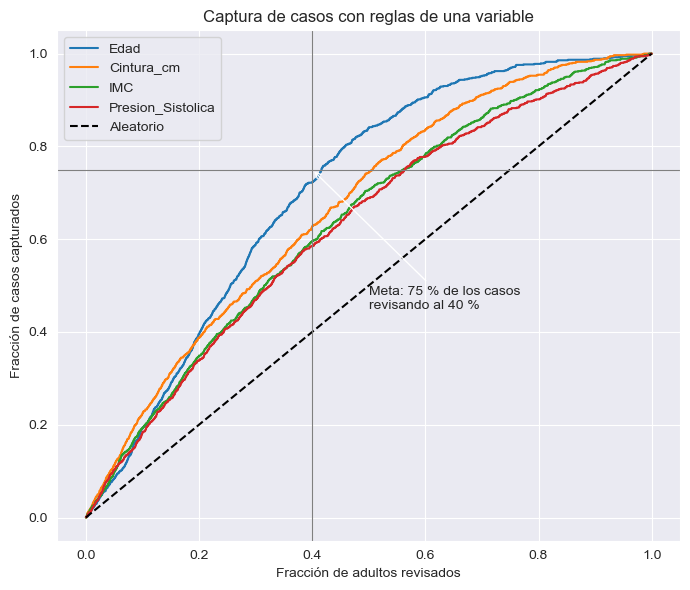

,Captura al 20%,Captura al 30%,Captura al 40%
Regla,,,
Edad,0.395,0.588,0.723
Cintura_cm,0.388,0.509,0.627
IMC,0.348,0.476,0.595
Presion_Sistolica,0.338,0.469,0.585


In [32]:
def curva_captura(puntaje, y):
    orden = np.argsort(-puntaje.values, kind="stable")
    acum = np.cumsum(y.values[orden]) / y.sum()
    return np.arange(1, len(y) + 1) / len(y), acum

y_ad = adultos["Diabetes"]
fig, ax = plt.subplots(figsize=(7, 6))
filas = []
for col in ["Edad", "Cintura_cm", "IMC", "Presion_Sistolica"]:
    puntaje = adultos[col].fillna(adultos[col].median())
    x, ycap = curva_captura(puntaje, y_ad)
    ax.plot(x, ycap, label=col)
    filas.append({"Regla": col,
                  **{f"Captura al {int(f * 100)}%": round(ycap[int(f * len(y_ad)) - 1], 3)
                     for f in (0.2, 0.3, 0.4)}})

ax.plot([0, 1], [0, 1], "k--", label="Aleatorio")
ax.axvline(0.4, color="gray", lw=0.8)
ax.axhline(0.75, color="gray", lw=0.8)
ax.annotate("Meta: 75 % de los casos\nrevisando al 40 %", (0.4, 0.75), (0.5, 0.45),
            arrowprops=dict(arrowstyle="->"))
ax.set_xlabel("Fracción de adultos revisados")
ax.set_ylabel("Fracción de casos capturados")
ax.set_title("Captura de casos con reglas de una variable")
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "eda_curva_captura_referencia.png", dpi=150)
plt.show()
pd.DataFrame(filas).set_index("Regla")

Cualquier variable le gana al azar. La edad es la mejor regla simple y captura cerca del 72 % de los casos revisando al 40 %, o sea que se acerca bastante a la meta. Las otras tres se quedan entre 58 % y 63 %.

Ninguna regla de una sola variable llega al 75 %. Además, usar solo la edad no sirve de mucho en la práctica porque no distingue entre dos personas de la misma edad. Hay señal para priorizar, pero toca combinar variables para pasar la línea base de la edad.

## 4. Conclusiones

| Qué encontramos | Qué hacemos |
|---|---|
| La base anterior tenía solo 21 casos | Usamos la base consolidada de NHANES, con 922 casos |
| Los niños casi no tienen casos (0,5 %) | Modelamos solo adultos: 6.110 personas y 902 positivos |
| Por cada positivo hay 5,8 negativos | Separamos train y test de forma estratificada, ponderamos clases y medimos recall, F1, ROC-AUC y PR-AUC |
| Faltan entre 4 % y 12 % de datos, igual en ambas clases | Rellenamos con la mediana dentro del pipeline |
| Presión diastólica en cero era un error de captura | La pasamos a nulo (32 casos) |
| Los valores extremos son posibles | No los quitamos |
| IMC y cintura son casi la misma información (0,91) | Probamos con una sola o con regularización |
| Edad, cintura, IMC y sistólica separan bien; la diastólica no | La diastólica queda como candidata a salir |
| Edad e IMC se refuerzan | Probamos interacciones y modelos de árboles |
| Solo con la edad se captura 72,3 % revisando al 40 % | El modelo tiene que superar eso y llegar a 75 % |
| El colesterol necesita sangre y su signo puede reflejar el tratamiento | Probamos los modelos con laboratorio y sin laboratorio |